# Symbolist learner: decision tree

## Preprocessing

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler


SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

# cleaning and sex encoding (fixed rules, before the split)
df = pl.read_csv("./data/abalone.csv.zst")
df = df.filter(~((pl.col("height") == 0) | (pl.col("height") > 0.3)))
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
).drop("sex")

# 20% hold-out test (not used until the end) and 5 stratified folds on the development part
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))
dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
X, rings = dev.select(FEATURES).to_numpy(), dev["rings"].to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y_bins[dev_idx]))


def cross_validate(fit_predict, verbose=True):
    """fit_predict(X_train, y_train, X_val) -> predictions. Standardization is fitted on each training part."""
    scores = []
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])
        pred = fit_predict(scaler.transform(X[tr]), rings[tr], scaler.transform(X[va]))
        scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
    scores = np.array(scores)
    m, sd = scores.mean(axis=0), scores.std(axis=0, ddof=1)
    if verbose:
        print(f"RMSE {m[0]:.3f} ± {sd[0]:.3f}   MAE {m[1]:.3f} ± {sd[1]:.3f}   R² {m[2]:.3f} ± {sd[2]:.3f}")
    return scores


baseline = cross_validate(lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))

RMSE 3.226 ± 0.159   MAE 2.366 ± 0.084   R² -0.001 ± 0.001


## Model: regression tree

A symbolist learns **rules**. A regression tree asks a sequence of yes/no questions about the features (`shell_weight <= 0.12?`) and every animal ends in a **leaf**; the prediction is the mean `rings` of the training animals in that leaf.

* A tree compares one feature with a threshold at a time, so it does not care about the scale of the features or about their correlations (standardization changes nothing).
* A deep tree memorizes the training animals (overfits); a shallow one is readable but coarse. The depth and the minimum leaf size control this.

In [2]:
from sklearn.tree import DecisionTreeRegressor, plot_tree


def tree(X_tr, y_tr, X_va, max_depth=None, min_samples_leaf=1, leaves=None):
    model = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED).fit(X_tr, y_tr)
    if leaves is not None:
        leaves.append(model.get_n_leaves())
    return model.predict(X_va)


print("unlimited tree: ", end="")
symbolist = cross_validate(tree)

unlimited tree: RMSE 2.968 ± 0.145   MAE 2.062 ± 0.103   R² 0.151 ± 0.062


### Tuning

Hyper-parameters are chosen on the 5 validation folds only. Among the configurations whose mean RMSE is within one standard error of the best one (`std / √5` of the best), the **simplest** is chosen: the tree with the fewest leaves (rules), and the lowest mean RMSE if several have the same size.

| Hyper-parameter | Values | Why |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, 10 | longest chain of questions: how detailed the rules can be |
| `min_samples_leaf` | 1, 5, 20, 50 | smallest group of animals a rule may describe, against rules that fit only a few animals |

In [3]:
from itertools import product

results = []
for max_depth, min_samples_leaf in product([2, 3, 4, 5, 6, 8, 10], [1, 5, 20, 50]):
    leaves = []
    scores = cross_validate(lambda X_tr, y_tr, X_va: tree(X_tr, y_tr, X_va, max_depth=max_depth, min_samples_leaf=min_samples_leaf, leaves=leaves), verbose=False)
    results.append((max_depth, min_samples_leaf, np.mean(leaves), scores[:, 0].mean(), scores[:, 0].std(ddof=1)))

tuning = pl.DataFrame(results, schema=["max_depth", "min_samples_leaf", "leaves", "mean RMSE", "std RMSE"], orient="row").sort("mean RMSE")

with pl.Config(tbl_rows=10):
    print(tuning)
top = tuning.row(0, named=True)
limit = top["mean RMSE"] + top["std RMSE"] / np.sqrt(len(folds))
best = tuning.filter(pl.col("mean RMSE") <= limit).sort(["leaves", "mean RMSE"]).row(0, named=True)
print("lowest mean RMSE:", {k: top[k] for k in ['max_depth', 'min_samples_leaf', 'leaves']}, f"RMSE {top['mean RMSE']:.3f}")
print("simplest within one standard error:", {k: best[k] for k in ['max_depth', 'min_samples_leaf', 'leaves']}, f"RMSE {best['mean RMSE']:.3f}, limit {limit:.3f}")

shape: (28, 5)
┌───────────┬──────────────────┬────────┬───────────┬──────────┐
│ max_depth ┆ min_samples_leaf ┆ leaves ┆ mean RMSE ┆ std RMSE │
│ ---       ┆ ---              ┆ ---    ┆ ---       ┆ ---      │
│ i64       ┆ i64              ┆ f64    ┆ f64       ┆ f64      │
╞═══════════╪══════════════════╪════════╪═══════════╪══════════╡
│ 10        ┆ 50               ┆ 41.6   ┆ 2.256767  ┆ 0.107221 │
│ 8         ┆ 50               ┆ 41.2   ┆ 2.257542  ┆ 0.106256 │
│ 6         ┆ 50               ┆ 35.0   ┆ 2.266669  ┆ 0.100647 │
│ 6         ┆ 20               ┆ 48.8   ┆ 2.289401  ┆ 0.089207 │
│ 10        ┆ 20               ┆ 103.0  ┆ 2.303014  ┆ 0.088901 │
│ …         ┆ …                ┆ …      ┆ …         ┆ …        │
│ 2         ┆ 1                ┆ 4.0    ┆ 2.586779  ┆ 0.125835 │
│ 2         ┆ 5                ┆ 4.0    ┆ 2.586779  ┆ 0.125835 │
│ 2         ┆ 20               ┆ 4.0    ┆ 2.586779  ┆ 0.125835 │
│ 2         ┆ 50               ┆ 4.0    ┆ 2.586779  ┆ 0.125835 │
│ 10      

### Depth against error

Training error always falls as the tree grows. With leaves of any size (`min_samples_leaf=1`) the validation error turns up after depth 5: the tree memorizes the training animals, and the gap between the two curves is the overfitting. With the chosen `min_samples_leaf=50` a leaf cannot get smaller than 50 animals, so the tree stops growing around depth 6 and the validation error stays flat.

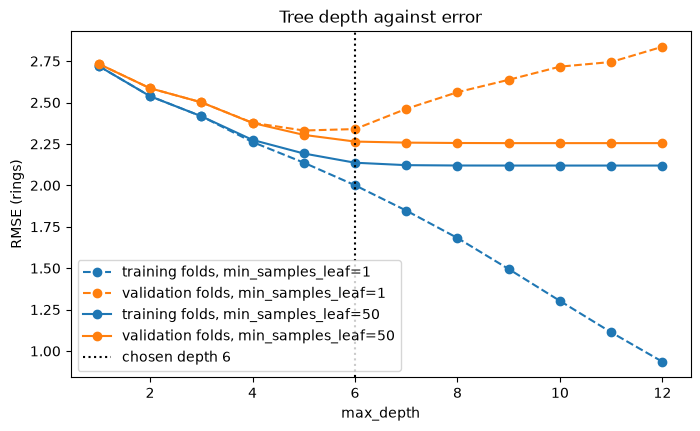

In [4]:
from pathlib import Path

curves = {}
for leaf in (1, best["min_samples_leaf"]):
    rows = []
    for d in range(1, 13):
        tr_rmse, va_rmse = [], []
        for tr, va in folds:
            m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf, random_state=SEED).fit(X[tr], rings[tr])
            tr_rmse.append(root_mean_squared_error(rings[tr], m.predict(X[tr])))
            va_rmse.append(root_mean_squared_error(rings[va], m.predict(X[va])))
        rows.append((np.mean(tr_rmse), np.mean(va_rmse)))
    curves[leaf] = np.array(rows).T

fig, ax = plt.subplots(figsize=(8, 4.5))
for (leaf, (tr_curve, va_curve)), ls in zip(curves.items(), ("--", "-")):
    ax.plot(range(1, 13), tr_curve, "o" + ls, color="C0", label=f"training folds, min_samples_leaf={leaf}")
    ax.plot(range(1, 13), va_curve, "o" + ls, color="C1", label=f"validation folds, min_samples_leaf={leaf}")
ax.axvline(best["max_depth"], color="k", ls=":", label=f"chosen depth {best['max_depth']}")
ax.set(title="Tree depth against error", xlabel="max_depth", ylabel="RMSE (rings)")
ax.legend()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/validation_curve_tree.png", dpi=150, bbox_inches="tight")
plt.show()

### The rules

The chosen tree fitted on the whole development part, only to read it (not to score it). Trees do not need scaling, so it is fitted on the original features to keep the thresholds readable.

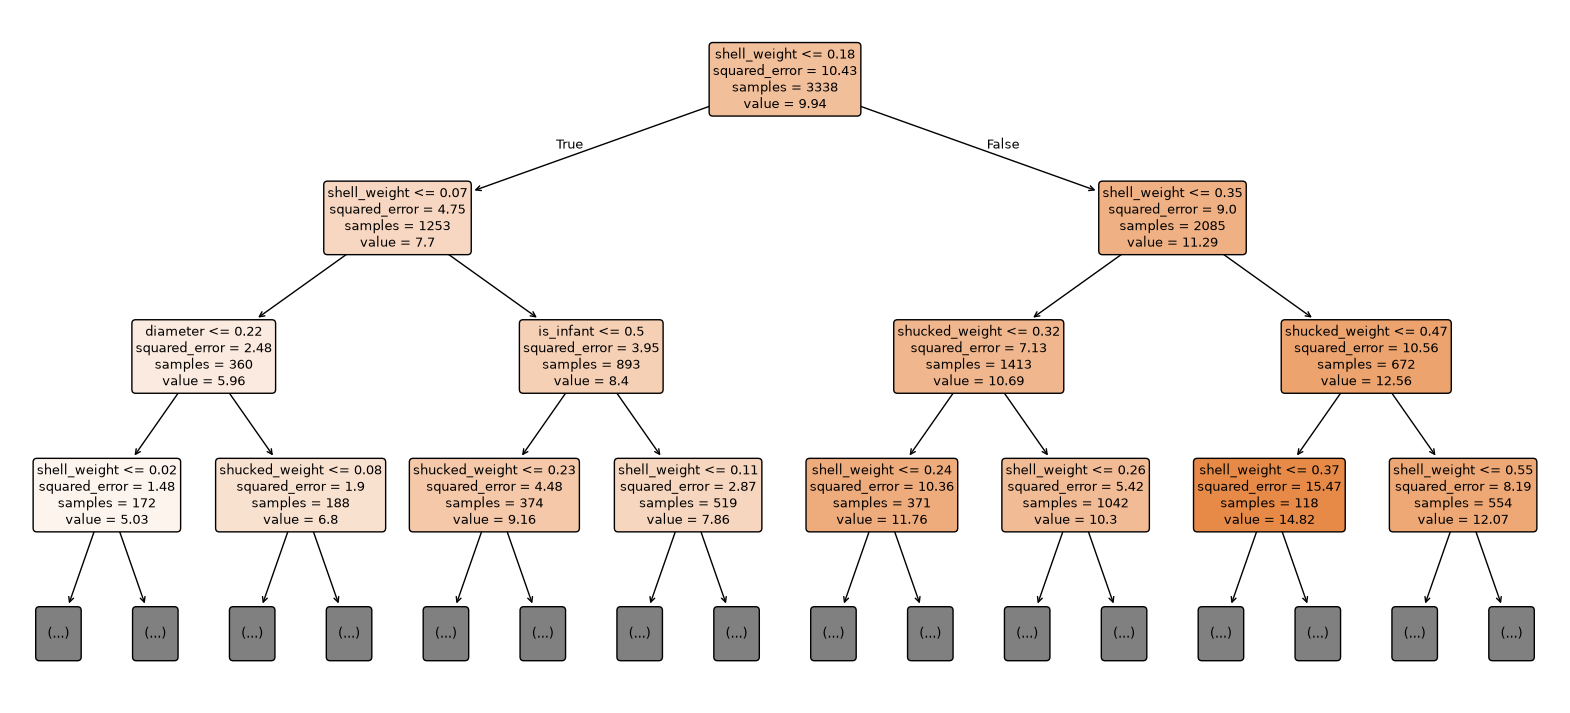

shape: (9, 2)
┌────────────────┬────────────┐
│ feature        ┆ importance │
│ ---            ┆ ---        │
│ str            ┆ f64        │
╞════════════════╪════════════╡
│ shell_weight   ┆ 0.803      │
│ shucked_weight ┆ 0.125      │
│ is_infant      ┆ 0.028      │
│ height         ┆ 0.017      │
│ diameter       ┆ 0.014      │
│ whole_weight   ┆ 0.01       │
│ is_female      ┆ 0.002      │
│ viscera_weight ┆ 0.001      │
│ length         ┆ 0.0        │
└────────────────┴────────────┘


In [5]:
reader = DecisionTreeRegressor(max_depth=best["max_depth"], min_samples_leaf=best["min_samples_leaf"], random_state=SEED).fit(X, rings)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(reader, feature_names=FEATURES, filled=True, rounded=True, precision=2, max_depth=3, fontsize=9, ax=ax)
fig.savefig("figures/tree_rules.png", dpi=150, bbox_inches="tight")
plt.show()
print(pl.DataFrame({"feature": FEATURES, "importance": reader.feature_importances_.round(3)}).sort("importance", descending=True))

## Final evaluation on the test set

The chosen hyper-parameters (simplest within one standard error of the best) are used to refit the model on the **whole development part** (3338 rows), and the model is scored **once** on the 20% test set (835 rows). Nothing is chosen from the test result.

baseline   test RMSE 3.207   MAE 2.351   R² -0.000
tree       test RMSE 2.289   MAE 1.595   R² 0.491


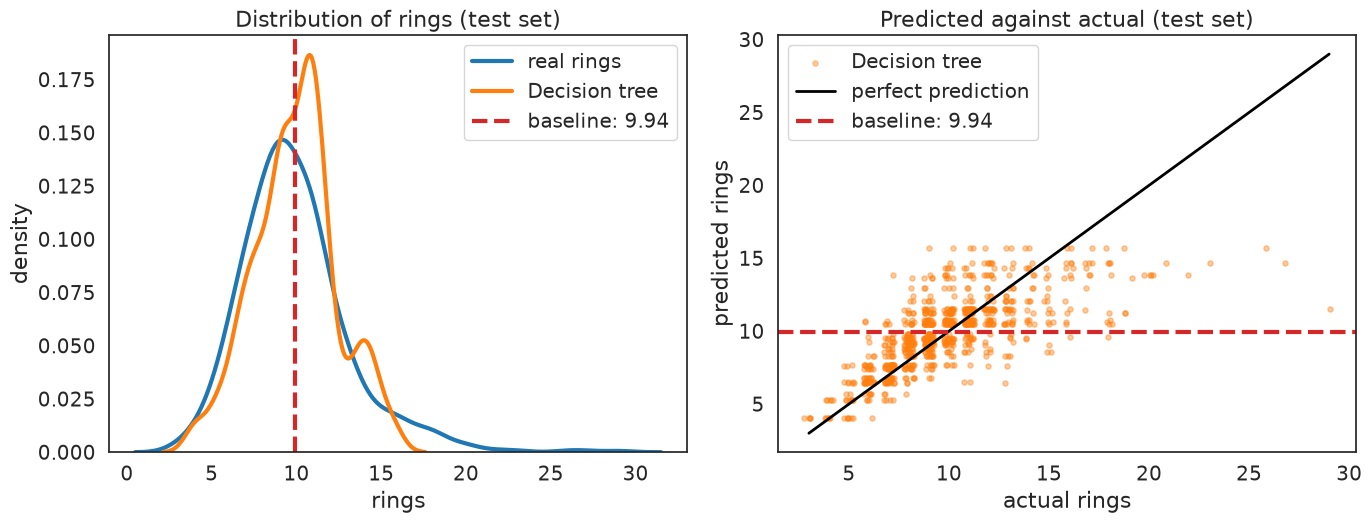

In [6]:
from pathlib import Path
import seaborn as sns
def test_evaluate(name, fit_predict):
    """Refit on the whole development part (standardized with its own mean and sd) and score once on the test set."""
    scaler = StandardScaler().fit(X)
    y = test["rings"].to_numpy()
    pred = fit_predict(scaler.transform(X), rings, scaler.transform(test.select(FEATURES).to_numpy()))
    print(f"{name:10s} test RMSE {root_mean_squared_error(y, pred):.3f}   MAE {mean_absolute_error(y, pred):.3f}   R² {r2_score(y, pred):.3f}")
    return pred


def plot_test(pred, name):
    """Left: distribution of the real rings, of the predictions and of the baseline. Right: predicted against actual."""
    y_test, base = test["rings"].to_numpy(), rings.mean()
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(y_test))  # rings are integers: spread the dots sideways
    with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.3):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.kdeplot(y_test, ax=ax1, lw=3, color="C0", label="real rings")
        sns.kdeplot(pred, ax=ax1, lw=3, color="C1", label=name)
        ax1.axvline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax1.set(title="Distribution of rings (test set)", xlabel="rings", ylabel="density")
        ax1.legend()
        ax2.scatter(y_test + jitter, pred, s=14, alpha=0.4, color="C1", label=name)
        ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="k", lw=2, label="perfect prediction")
        ax2.axhline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax2.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings")
        ax2.legend()
        plt.tight_layout()
        plt.show()


test_evaluate("baseline", lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))
final = lambda X_tr, y_tr, X_va: tree(X_tr, y_tr, X_va, max_depth=best["max_depth"], min_samples_leaf=best["min_samples_leaf"])
pred = test_evaluate("tree", final)
plot_test(pred, "Decision tree")

# validation scores of the chosen model and its test predictions, for the comparison in evaluation.ipynb
val = cross_validate(final, verbose=False)
Path("results").mkdir(exist_ok=True)
np.savez("results/symbolists.npz", val_rmse=val[:, 0], baseline_rmse=baseline[:, 0], test_y=test["rings"].to_numpy(), test_pred=pred)